In [2]:
import os
import pandas as p

In [3]:
ARCHIVO_PQ = "data/contaminantes_gran_concepcion.parquet"

In [4]:
if os.path.exists(ARCHIVO_PQ):
    datos = pd.read_parquet(ARCHIVO_PQ)
    print(f"Cargado desde parquet: {len(datos):,} filas")
else:
    print("Descargando todo el histórico... (tarda varios minutos)")
    datos = traer_estaciones(ESTACIONES, CONTAMINANTES, "110101", "260711")
    datos.to_parquet(ARCHIVO_PQ, index=False)
    print(f"Guardado: {len(datos):,} filas")

print(f"Estaciones: {datos['estacion'].nunique()}")
print(f"Parámetros: {list(datos['parametro'].unique())}")
print(f"Rango: {datos['timestamp'].min()} a {datos['timestamp'].max()}")

Cargado desde parquet: 7,973,661 filas
Estaciones: 16
Parámetros: ['mp2.5', 'mp10', 'so2', 'no', 'no2', 'nox', 'co', 'o3']
Rango: 2011-01-01 01:00:00 a 2026-07-11 23:00:00


In [5]:
datos.head()

,timestamp,valor,estado,codigo,estacion,comuna,parametro
0,2015-08-18 21:00:00,6.729,preliminar,854,Punteras,Chiguayante,mp2.5
1,2015-08-22 14:00:00,1.426,no_validado,854,Punteras,Chiguayante,mp2.5
2,2015-08-22 15:00:00,3.392,no_validado,854,Punteras,Chiguayante,mp2.5
3,2015-08-22 16:00:00,2.708,no_validado,854,Punteras,Chiguayante,mp2.5
4,2015-08-22 17:00:00,1.777,no_validado,854,Punteras,Chiguayante,mp2.5


In [6]:
# Pasar a formato ancho: una fila por timestamp + estación
ancho = datos.pivot_table(
    index=["timestamp", "estacion", "comuna"],
    columns="parametro",
    values="valor",
    aggfunc="mean"
).reset_index()
ancho.columns.name = None

print(f"Formato ancho: {ancho.shape[0]:,} filas x {ancho.shape[1]} columnas")
print(f"Columnas: {list(ancho.columns)}")
ancho.head()

Formato ancho: 1,638,379 filas x 11 columnas
Columnas: ['timestamp', 'estacion', 'comuna', 'co', 'mp10', 'mp2.5', 'no', 'no2', 'nox', 'o3', 'so2']


,timestamp,estacion,comuna,co,mp10,mp2.5,no,no2,nox,o3,so2
0,2011-01-01 01:00:00,Bocatoma,Hualpen,NaN,8.80315,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-01 01:00:00,ENAP Price,Hualpen,0.174279,8.67415,NaN,NaN,0.378759,NaN,10.09590,0.775164
2,2011-01-01 01:00:00,Indura,Talcahuano,0.294612,11.12580,NaN,NaN,1.513970,NaN,9.30829,NaN
3,2011-01-01 01:00:00,Inpesca,Talcahuano,NaN,15.75080,NaN,NaN,NaN,NaN,NaN,0.047096
4,2011-01-01 01:00:00,JUNJI,Hualpen,0.308646,24.20920,NaN,NaN,3.420190,NaN,10.11940,2.056570


In [7]:
# ¿Qué % de datos tiene cada contaminante?
contaminantes = ["mp2.5", "mp10", "so2", "no", "no2", "nox", "co", "o3"]
contaminantes = [c for c in contaminantes if c in ancho.columns]

print("COMPLETITUD POR CONTAMINANTE (sobre el total de filas)")
print("-" * 55)
for c in contaminantes:
    pct = ancho[c].notna().mean() * 100
    n = ancho[c].notna().sum()
    print(f"  {c:8} {pct:5.1f}%   ({n:,} mediciones)")

COMPLETITUD POR CONTAMINANTE (sobre el total de filas)
-------------------------------------------------------
  mp2.5     72.9%   (1,194,216 mediciones)
  mp10      94.5%   (1,547,923 mediciones)
  so2       77.3%   (1,266,446 mediciones)
  no        35.1%   (575,650 mediciones)
  no2       64.7%   (1,060,398 mediciones)
  nox       36.4%   (595,569 mediciones)
  co        48.9%   (800,925 mediciones)
  o3        56.9%   (932,534 mediciones)


In [8]:
print("COMPLETITUD (%) POR ESTACIÓN Y CONTAMINANTE")
comp_est = ancho.groupby("estacion")[contaminantes].apply(lambda g: g.notna().mean() * 100).round(0)
print(comp_est)

COMPLETITUD (%) POR ESTACIÓN Y CONTAMINANTE
                         mp2.5   mp10    so2     no    no2    nox    co     o3
estacion                                                                      
Bocatoma                  62.0   79.0   82.0    0.0    0.0    0.0   0.0    0.0
Cerro Merquin             74.0   85.0   17.0    0.0    0.0    0.0   0.0    0.0
Consultorio San Vicente   65.0   99.0   65.0   65.0   64.0   65.0   0.0    0.0
Coronel Norte             97.0   96.0  100.0  100.0  100.0  100.0  44.0  100.0
ENAP Price                79.0   98.0   98.0    0.0   97.0    0.0  97.0   98.0
Escuadron ENEL            95.0   94.0   52.0   35.0   74.0   34.0  90.0   88.0
Escuadron ENESA          100.0  100.0    0.0    0.0    0.0    0.0   0.0    0.0
Hualqui                   87.0   88.0   84.0   87.0   87.0   87.0   0.0   98.0
Indura                    60.0   94.0   98.0    0.0   98.0    0.0  99.0   99.0
Inpesca                   72.0   96.0   99.0    0.0    0.0    0.0   0.0    0.0
JUNJI   

In [9]:
ancho["anio"] = ancho["timestamp"].dt.year
print("COMPLETITUD (%) DE MP2.5 POR AÑO")
print(ancho.groupby("anio")["mp2.5"].apply(lambda x: x.notna().mean()*100).round(0))

COMPLETITUD (%) DE MP2.5 POR AÑO
anio
2011     0.0
2012     2.0
2013    12.0
2014     7.0
2015    34.0
2016    71.0
2017    97.0
2018    98.0
2019    99.0
2020    91.0
2021    98.0
2022    97.0
2023    95.0
2024    92.0
2025    99.0
2026    99.0
Name: mp2.5, dtype: float64


In [10]:
 # Filtrar al período con buena cobertura
ancho_filtrado = ancho[ancho["anio"] >= 2017]

print(f"Filas antes:   {len(ancho):,}")
print(f"Filas después: {len(ancho_filtrado):,}")
print(f"\nCompletitud de mp2.5 en el período filtrado: {ancho_filtrado['mp2.5'].notna().mean()*100:.1f}%")

Filas antes:   1,638,379
Filas después: 1,119,082

Completitud de mp2.5 en el período filtrado: 96.4%


In [11]:
print("COMPLETITUD (%) POR ESTACIÓN — período 2017-2026")
comp = ancho_filtrado.groupby("estacion")[contaminantes].apply(lambda g: g.notna().mean()*100).round(0)
print(comp)

COMPLETITUD (%) POR ESTACIÓN — período 2017-2026
                         mp2.5   mp10    so2     no    no2    nox    co     o3
estacion                                                                      
Bocatoma                  73.0   73.0   99.0    0.0    0.0    0.0   0.0    0.0
Cerro Merquin            100.0   80.0    0.0    0.0    0.0    0.0   0.0    0.0
Consultorio San Vicente   98.0   98.0   98.0   98.0   98.0   98.0   0.0    0.0
Coronel Norte             97.0   96.0  100.0  100.0  100.0  100.0  44.0  100.0
ENAP Price                98.0   98.0   98.0    0.0   97.0    0.0  99.0   99.0
Escuadron ENEL            95.0   94.0   52.0   35.0   74.0   34.0  90.0   88.0
Escuadron ENESA          100.0  100.0    0.0    0.0    0.0    0.0   0.0    0.0
Hualqui                   99.0   99.0   95.0   98.0   98.0   98.0   0.0   98.0
Indura                    97.0   98.0   99.0    0.0   98.0    0.0  99.0   99.0
Inpesca                   99.0   99.0   99.0    0.0    0.0    0.0   0.0    0.0
JUN

In [17]:
# DECISIÓN: todas las estaciones, período 2017-2026
dataset = ancho[ancho["anio"] >= 2017].copy()

print(f"Filas: {len(dataset):,}")
print(f"Estaciones: {dataset['estacion'].nunique()}")
print(f"Rango: {dataset['timestamp'].min()} a {dataset['timestamp'].max()}")
print(f"\nCompletitud mp2.5: {dataset['mp2.5'].notna().mean()*100:.1f}%")
print(f"\nCompletitud mp10: {dataset['mp10'].notna().mean()*100:.1f}%")
print(f"\nCompletitud so2: {dataset['so2'].notna().mean()*100:.1f}%")
print(f"\nCompletitud no: {dataset['no'].notna().mean()*100:.1f}%")
print(f"\nCompletitud no2: {dataset['no2'].notna().mean()*100:.1f}%")
print(f"\nCompletitud nox: {dataset['nox'].notna().mean()*100:.1f}%")
print(f"\nCompletitud co: {dataset['co'].notna().mean()*100:.1f}%")
print(f"\nCompletitud o3: {dataset['o3'].notna().mean()*100:.1f}%")

Filas: 1,119,082
Estaciones: 16
Rango: 2017-01-01 00:00:00 a 2026-07-11 23:00:00

Completitud mp2.5: 96.4%

Completitud mp10: 94.9%

Completitud so2: 84.3%

Completitud no: 42.8%

Completitud no2: 71.2%

Completitud nox: 43.1%

Completitud co: 46.4%

Completitud o3: 57.6%


In [18]:
# Guardar el dataset base
dataset.to_parquet("data/dataset_base_2017_2026.parquet", index=False)
print(f"Guardado: {len(dataset):,} filas")
print(f"Columnas: {list(dataset.columns)}")

Guardado: 1,119,082 filas
Columnas: ['timestamp', 'estacion', 'comuna', 'co', 'mp10', 'mp2.5', 'no', 'no2', 'nox', 'o3', 'so2', 'anio']


In [19]:
# Promedio diario de MP2.5 por estación (regla del 75%: mínimo 18 de 24 horas)
dataset["fecha"] = dataset["timestamp"].dt.floor("D")

diario = dataset.groupby(["fecha", "estacion", "comuna"]).agg(
    mp25=("mp2.5", "mean"),
    n_horas=("mp2.5", "count")
).reset_index()

# Solo días válidos (>= 18 horas medidas)
diario["valido"] = diario["n_horas"] >= 18

print(f"Días-estación totales: {len(diario):,}")
print(f"Días válidos (>=18h):  {diario['valido'].sum():,} ({diario['valido'].mean()*100:.1f}%)")
print(f"\nRango de MP2.5 diario: {diario['mp25'].min():.1f} a {diario['mp25'].max():.1f} µg/m³")

Días-estación totales: 47,174
Días válidos (>=18h):  44,768 (94.9%)

Rango de MP2.5 diario: 0.0 a 791.9 µg/m³


In [20]:
import numpy as np

# Umbrales oficiales MP2.5 (DS 12/2011, promedio 24h)
def clasificar(v):
    if pd.isna(v):   return np.nan
    if v < 50:       return "Bueno"
    if v < 80:       return "Regular"
    if v < 110:      return "Alerta"
    if v < 170:      return "Preemergencia"
    return "Emergencia"

# Solo días válidos
diario_valido = diario[diario["valido"]].copy()
diario_valido["episodio"] = diario_valido["mp25"].apply(clasificar)

print("EPISODIOS POR ESTACIÓN-DÍA (2017-2026)")
print(diario_valido["episodio"].value_counts())
print(f"\nEpisodios críticos (Alerta+): {diario_valido['episodio'].isin(['Alerta','Preemergencia','Emergencia']).sum():,}")

EPISODIOS POR ESTACIÓN-DÍA (2017-2026)
episodio
Bueno            41980
Regular           1998
Alerta             509
Preemergencia      224
Emergencia          57
Name: count, dtype: int64

Episodios críticos (Alerta+): 790


In [21]:
# Episodio de cuenca: se toma el MÁXIMO entre estaciones de cada día
cuenca = diario_valido.groupby("fecha").agg(
    mp25_max=("mp25", "max"),
    estacion_max=("estacion", lambda x: x.iloc[0]),   # provisorio
    n_estaciones=("estacion", "count")
).reset_index()

cuenca["episodio"] = cuenca["mp25_max"].apply(clasificar)

print("EPISODIOS DE CUENCA (2017-2026)")
print(cuenca["episodio"].value_counts())
print(f"\nTotal de días: {len(cuenca):,}")
print(f"Días críticos (Alerta+): {cuenca['episodio'].isin(['Alerta','Preemergencia','Emergencia']).sum():,}")

EPISODIOS DE CUENCA (2017-2026)
episodio
Bueno            2589
Regular           470
Alerta            228
Preemergencia     140
Emergencia         52
Name: count, dtype: int64

Total de días: 3,479
Días críticos (Alerta+): 420


In [22]:
# ¿Qué estaciones son las que más gatillan episodios?
criticos = diario_valido[diario_valido["episodio"].isin(["Alerta","Preemergencia","Emergencia"])]

print("DÍAS CRÍTICOS POR ESTACIÓN")
print(criticos.groupby(["comuna","estacion"]).size().sort_values(ascending=False))

DÍAS CRÍTICOS POR ESTACIÓN
comuna       estacion               
Hualpen      JUNJI                      215
Coronel      Coronel Norte              181
Talcahuano   Inpesca                    162
             Consultorio San Vicente     81
Coronel      Lota urbana                 32
             Lagunillas ENEL             27
Hualqui      Hualqui                     27
Coronel      Lota rural                  20
             Cerro Merquin               11
Chiguayante  Punteras                     9
Coronel      Escuadron ENESA              6
Concepcion   Kingston College             5
Coronel      Escuadron ENEL               5
Talcahuano   Indura                       5
Hualpen      Bocatoma                     2
             ENAP Price                   2
dtype: int64


In [23]:
# Episodios críticos por mes del año
cuenca["mes"] = cuenca["fecha"].dt.month
cuenca["critico"] = cuenca["episodio"].isin(["Alerta","Preemergencia","Emergencia"])

print("DÍAS CRÍTICOS POR MES (2017-2026)")
por_mes = cuenca.groupby("mes").agg(
    dias_totales=("critico", "size"),
    dias_criticos=("critico", "sum"),
    mp25_promedio=("mp25_max", "mean")
).round(1)
por_mes["% critico"] = (100 * por_mes.dias_criticos / por_mes.dias_totales).round(1)
print(por_mes)

DÍAS CRÍTICOS POR MES (2017-2026)
     dias_totales  dias_criticos  mp25_promedio  % critico
mes                                                       
1             310              5           20.9        1.6
2             282             10           26.0        3.5
3             310              3           22.2        1.0
4             300             10           37.4        3.3
5             310            116           79.0       37.4
6             300            108           74.8       36.0
7             290            116           77.9       40.0
8             279             39           52.3       14.0
9             270              5           33.1        1.9
10            279              3           23.9        1.1
11            270              1           17.7        0.4
12            279              4           19.4        1.4


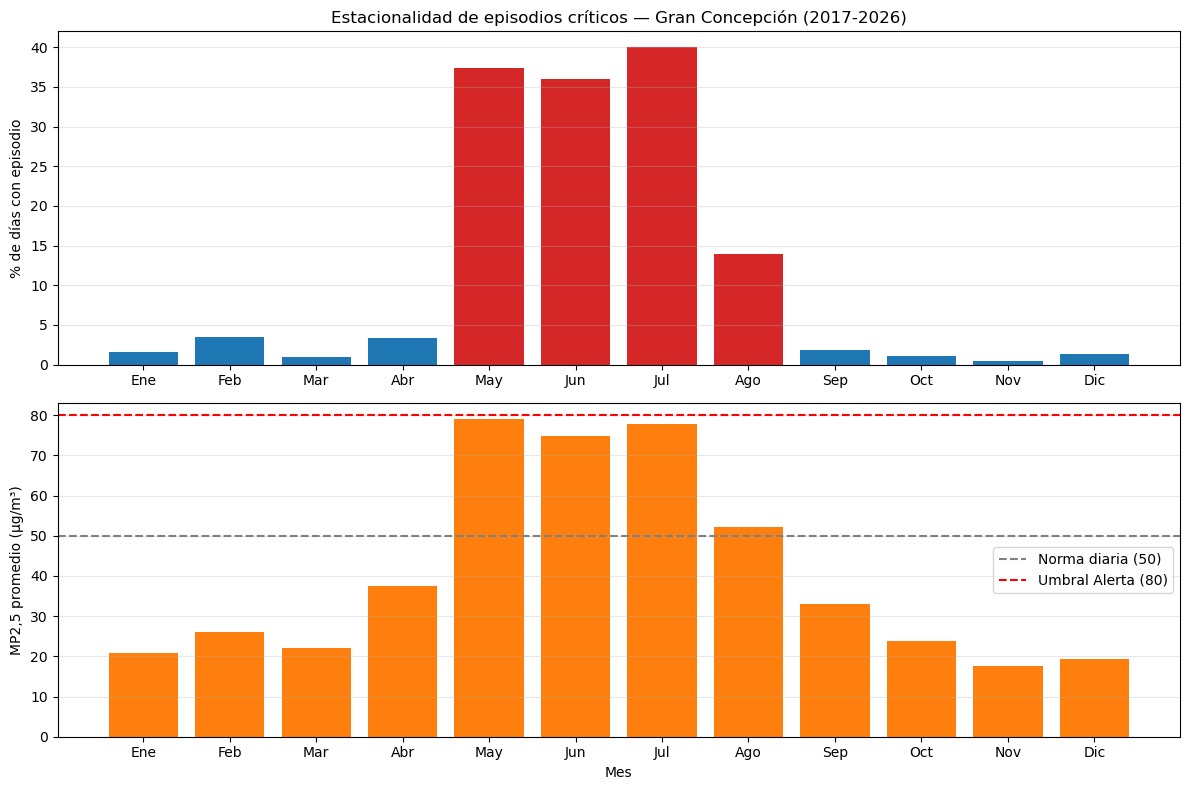

In [24]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# Gráfico 1: % de días críticos por mes
meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
colores = ["#d62728" if v > 10 else "#1f77b4" for v in por_mes["% critico"]]
ax1.bar(meses, por_mes["% critico"], color=colores)
ax1.set_ylabel("% de días con episodio")
ax1.set_title("Estacionalidad de episodios críticos — Gran Concepción (2017-2026)")
ax1.grid(axis="y", alpha=0.3)

# Gráfico 2: MP2.5 promedio por mes
ax2.bar(meses, por_mes["mp25_promedio"], color="#ff7f0e")
ax2.axhline(50, color="gray", linestyle="--", label="Norma diaria (50)")
ax2.axhline(80, color="red", linestyle="--", label="Umbral Alerta (80)")
ax2.set_ylabel("MP2,5 promedio (µg/m³)")
ax2.set_xlabel("Mes")
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()